# 사바나 동물 3종(타조·영양·코뿔소) 객체 탐지 및 추적

- **목표**: COCO 사전학습 클래스에 없는 타조(ostrich), 영양(antelope), 코뿔소(rhino)를 YOLOv8로 전이학습하고, 영상에서 탐지·추적한다.
- **데이터**: Open Images V7 (bounding box 라벨 포함)
- **모델**: YOLOv8s (Ultralytics) / **추적기**: ByteTrack
- **환경**: Google Colab, Tesla T4 GPU

## 1. 환경 설정

Ultralytics를 설치하고, Open Images 이미지 다운로드에 사용할 공식 스크립트(`downloader.py`)를 받는다.

In [1]:
!pip -q install ultralytics boto3
!wget -q -O /content/downloader.py https://raw.githubusercontent.com/openimages/dataset/master/downloader.py
import ultralytics
ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.2/112.6 GB disk)


## 2. 데이터 수집 및 YOLO 형식 변환

- Open Images V7에서 `Ostrich`, `Antelope`, `Rhinoceros` 클래스의 박스 라벨과 이미지를 수집한다.
- 영상 속 동물이 가젤인지 다른 영양인지 확실하지 않아, 상위 분류인 `Antelope` 클래스를 사용한다.
- 그림·조각상처럼 실물이 아닌 이미지(`IsDepiction`)와 여러 개체를 하나의 박스로 묶은 라벨(`IsGroupOf`)이 포함된 이미지는 제외한다.
- 학습 데이터는 Open Images train 세트에서 클래스별 최대 400장을 무작위로 뽑고, 검증 데이터는 validation + test 세트를 사용한다.
- 라벨은 `(XMin, XMax, YMin, YMax)` 형식을 YOLO 형식 `(클래스, 중심 x, 중심 y, 너비, 높이)`(0~1 정규화)로 변환한다.

In [2]:
import os, glob, shutil, random, subprocess
import pandas as pd

CLASSES = {"Ostrich": "ostrich", "Antelope": "antelope", "Rhinoceros": "rhino"}   # Open Images 클래스명 → 학습 클래스명
MAX_TRAIN_PER_CLASS = 400
DST_DIR = "/content/safari3"
RAW_DIR = "/content/oi_raw"
random.seed(0)

URLS = {
    "classes": "https://storage.googleapis.com/openimages/v7/oidv7-class-descriptions-boxable.csv",
    "train": "https://storage.googleapis.com/openimages/v6/oidv6-train-annotations-bbox.csv",
    "validation": "https://storage.googleapis.com/openimages/v5/validation-annotations-bbox.csv",
    "test": "https://storage.googleapis.com/openimages/v5/test-annotations-bbox.csv",
}
os.makedirs("/content/oi_csv", exist_ok=True)
for k, u in URLS.items():
    path = f"/content/oi_csv/{k}.csv"
    if not os.path.exists(path):
        print("다운로드:", k)
        subprocess.run(["wget", "-q", "-O", path, u], check=True)

# 클래스 이름 → Open Images 내부 ID(MID)
desc = pd.read_csv("/content/oi_csv/classes.csv", header=None, names=["LabelName", "DisplayName"])
desc = desc[desc.LabelName != "LabelName"]
mid_to_new = {}
for oi_name, new_name in CLASSES.items():
    row = desc[desc.DisplayName == oi_name]
    assert len(row) == 1, f"{oi_name} 클래스를 못 찾음"
    mid_to_new[row.LabelName.iloc[0]] = new_name
NAMES = list(CLASSES.values())
print("클래스:", {v: k for k, v in mid_to_new.items()})

COLS = ["ImageID", "LabelName", "XMin", "XMax", "YMin", "YMax", "IsGroupOf", "IsDepiction"]
def load_boxes(split):
    parts = []
    for chunk in pd.read_csv(f"/content/oi_csv/{split}.csv", usecols=COLS, chunksize=2_000_000):
        parts.append(chunk[chunk.LabelName.isin(mid_to_new)])
    df = pd.concat(parts)
    bad = df[(df.IsGroupOf == 1) | (df.IsDepiction == 1)].ImageID.unique()
    df = df[~df.ImageID.isin(bad)].copy()
    df["cls"] = df.LabelName.map(lambda m: NAMES.index(mid_to_new[m]))
    df["split"] = split
    return df

train_df = load_boxes("train")
val_df = pd.concat([load_boxes("validation"), load_boxes("test")])

# 학습 데이터: 클래스별 최대 MAX_TRAIN_PER_CLASS장 무작위 선택
chosen = set()
for c in range(len(NAMES)):
    ids = sorted(train_df[train_df.cls == c].ImageID.unique())
    random.shuffle(ids)
    chosen.update(ids[:MAX_TRAIN_PER_CLASS])
train_df = train_df[train_df.ImageID.isin(chosen)]

# Open Images 공식 downloader.py로 이미지 다운로드
os.makedirs(RAW_DIR, exist_ok=True)
pairs = pd.concat([train_df, val_df])[["split", "ImageID"]].drop_duplicates()
with open("/content/oi_list.txt", "w") as f:
    for s, i in pairs.itertuples(index=False):
        f.write(f"{s}/{i}\n")
print(f"사진 {len(pairs)}장 다운로드 시작")
subprocess.run(["python", "/content/downloader.py", "/content/oi_list.txt",
                f"--download_folder={RAW_DIR}", "--num_processes=16"], check=False)

# YOLO 형식 변환: 클래스 중심x 중심y 너비 높이 (0~1 정규화)
if os.path.exists(DST_DIR):
    shutil.rmtree(DST_DIR)
for yolo_split, df in [("train", train_df), ("valid", val_df)]:
    os.makedirs(f"{DST_DIR}/{yolo_split}/images")
    os.makedirs(f"{DST_DIR}/{yolo_split}/labels")
    n = 0
    for img_id, g in df.groupby("ImageID"):
        src = f"{RAW_DIR}/{img_id}.jpg"
        if not os.path.exists(src):
            continue
        shutil.copy(src, f"{DST_DIR}/{yolo_split}/images/{img_id}.jpg")
        with open(f"{DST_DIR}/{yolo_split}/labels/{img_id}.txt", "w") as f:
            for r in g.itertuples():
                cx, cy = (r.XMin + r.XMax) / 2, (r.YMin + r.YMax) / 2
                w, h = r.XMax - r.XMin, r.YMax - r.YMin
                f.write(f"{r.cls} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")
        n += 1
    print(f"{yolo_split}: {n}장 준비")

import yaml
DATA_YAML = f"{DST_DIR}/data.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump({"path": DST_DIR, "train": "train/images", "val": "valid/images", "names": NAMES}, f)
print("data.yaml 생성:", DATA_YAML)

다운로드: classes
다운로드: train
다운로드: validation
다운로드: test
클래스: {'ostrich': '/m/05n4y', 'antelope': '/m/0czz2', 'rhino': '/m/03d443'}
사진 1621장 다운로드 시작
train: 1113장 준비
valid: 508장 준비
data.yaml 생성: /content/safari3/data.yaml


## 3. 클래스별 데이터 수량 확인

과제 조건(클래스별 이미지 100장 이상)을 확인한다. Open Images에는 증강 복사본이 없으므로 아래 숫자가 원본 이미지 수다.

In [3]:
from collections import Counter
total = Counter()
for split in ["train", "valid"]:
    img_cnt, box_cnt = Counter(), Counter()
    for lbl in glob.glob(f"{DST_DIR}/{split}/labels/*.txt"):
        ids = [int(l.split()[0]) for l in open(lbl) if l.strip()]
        box_cnt.update(ids)
        img_cnt.update(set(ids))
    print(f"[{split}]", {NAMES[k]: f"{img_cnt[k]}장/{box_cnt[k]}박스" for k in range(len(NAMES))})
    total += img_cnt
print()
for k, c in enumerate(NAMES):
    print(f"{c:8s} 사진 {total[k]:4d}장  -> {'OK' if total[k] >= 100 else '부족!'}")

[train] {'ostrich': '314장/494박스', 'antelope': '401장/708박스', 'rhino': '400장/571박스'}
[valid] {'ostrich': '115장/153박스', 'antelope': '333장/574박스', 'rhino': '62장/85박스'}

ostrich  사진  429장  -> OK
antelope 사진  734장  -> OK
rhino    사진  462장  -> OK


## 4. 학습 전 기본 모델 결과 (COCO 사전학습 YOLOv8n)

COCO 80개 클래스에는 타조·영양·코뿔소가 없다. 기본 모델은 타조를 `bird`, 영양과 코뿔소를 `horse`/`cow` 등으로 탐지하며, 세 동물을 구분하지 못한다. 따라서 커스텀 학습이 필요하다.

Results saved to /content/runs/before_train


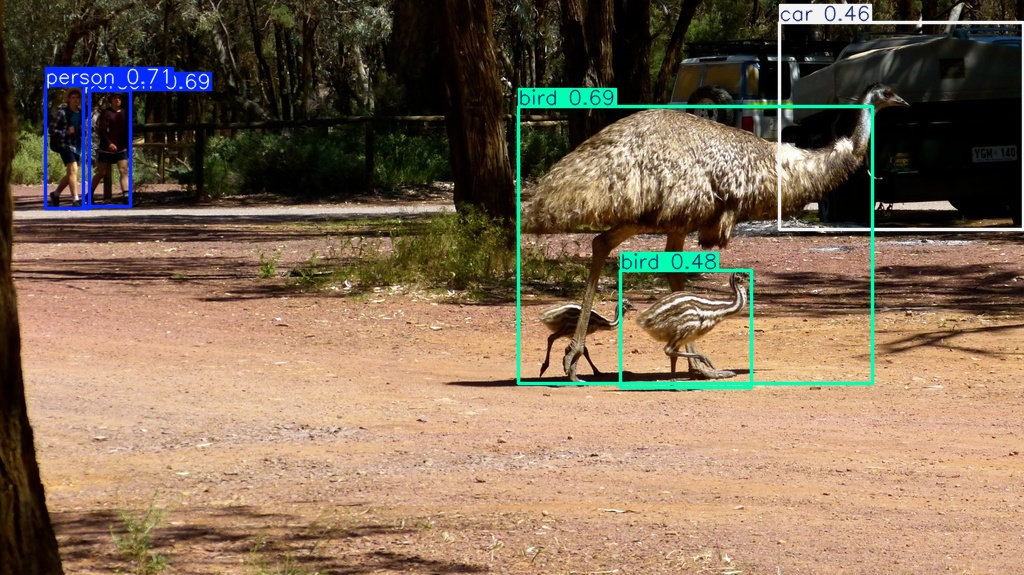

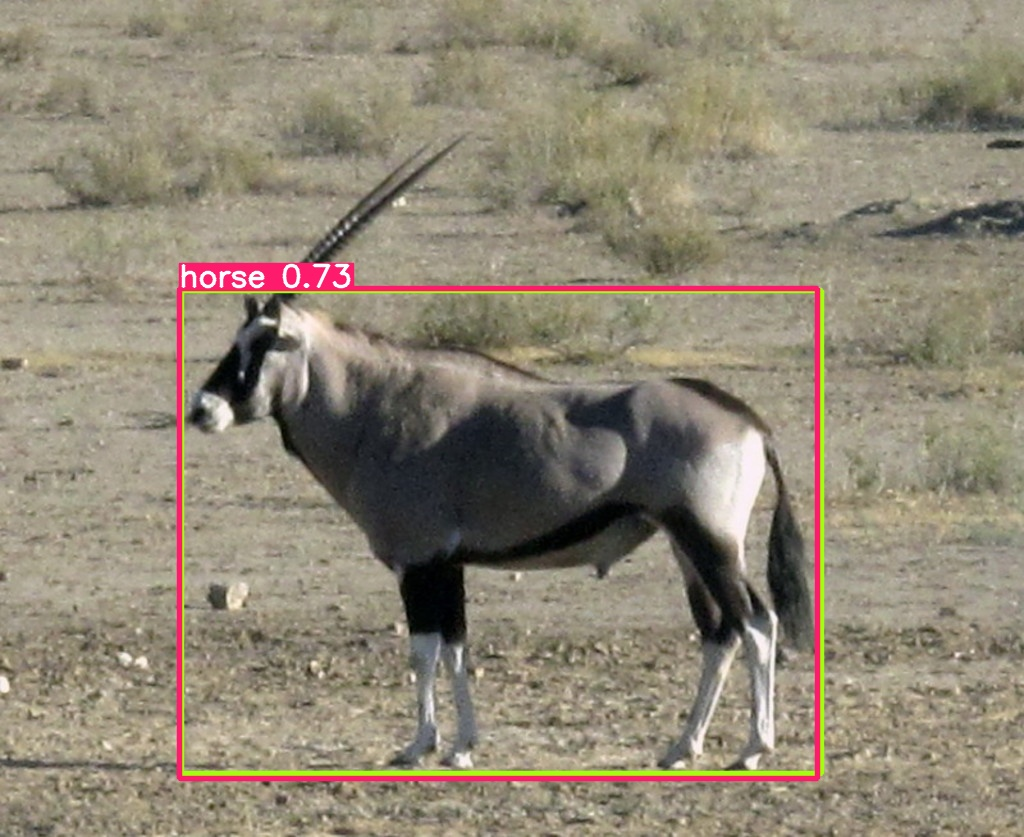

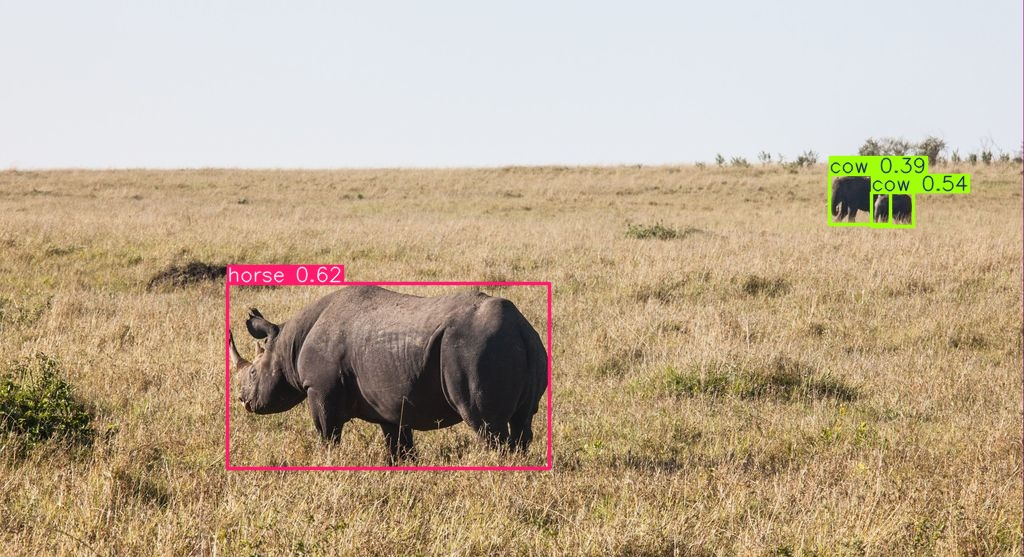

In [4]:
from ultralytics import YOLO
from IPython.display import Image, display

base = YOLO("yolov8n.pt")
samples = []
for k in range(len(NAMES)):   # 클래스마다 한 장씩
    for lbl in sorted(glob.glob(f"{DST_DIR}/valid/labels/*.txt")):
        if str(k) in {l.split()[0] for l in open(lbl)}:
            samples.append(lbl.replace("/labels/", "/images/").replace(".txt", ".jpg"))
            break
base.predict(samples, save=True, project="/content/runs", name="before_train", exist_ok=True, verbose=False)
for p in sorted(glob.glob("/content/runs/before_train/*"))[:3]:
    display(Image(filename=p, width=500))

## 5. 학습

YOLOv8s 사전학습 가중치에서 시작해 출력층을 3개 클래스로 바꿔 전이학습한다. YOLOv8n보다 큰 s 모델을 사용해 처음 보는 영상에서의 일반화 성능을 높이고자 했다.

- epochs 50, 입력 크기 640, batch 16, early stopping patience 15

In [5]:
model = YOLO("yolov8s.pt")
model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="/content/runs",
    name="safari3",
    exist_ok=True,
)
RUN_DIR = str(model.trainer.save_dir)
BEST = os.path.join(RUN_DIR, "weights", "best.pt")
print("최고 성능 가중치:", BEST)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/safari3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=safari3, nbs=64, nms=None, opset=None, optimize=False, optimize

## 6. 성능 평가

검증 데이터(508장)에서 Precision, Recall, mAP50, mAP50-95를 측정하고 학습 곡선과 혼동행렬을 확인한다.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2809.7±1206.1 MB/s, size: 261.8 KB)
val: Scanning /content/safari3/valid/labels.cache... 508 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 508/508 152.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.6it/s 8.8s
                   all        508        812      0.928      0.871      0.914       0.75
               ostrich        115        153      0.947      0.869      0.897      0.712
              antelope        333        574      0.901      0.803      0.882      0.704
                 rhino         62         85      0.937      0.941      0.964      0.834
Speed: 1.5ms preprocess, 6.5ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val
mAP50   

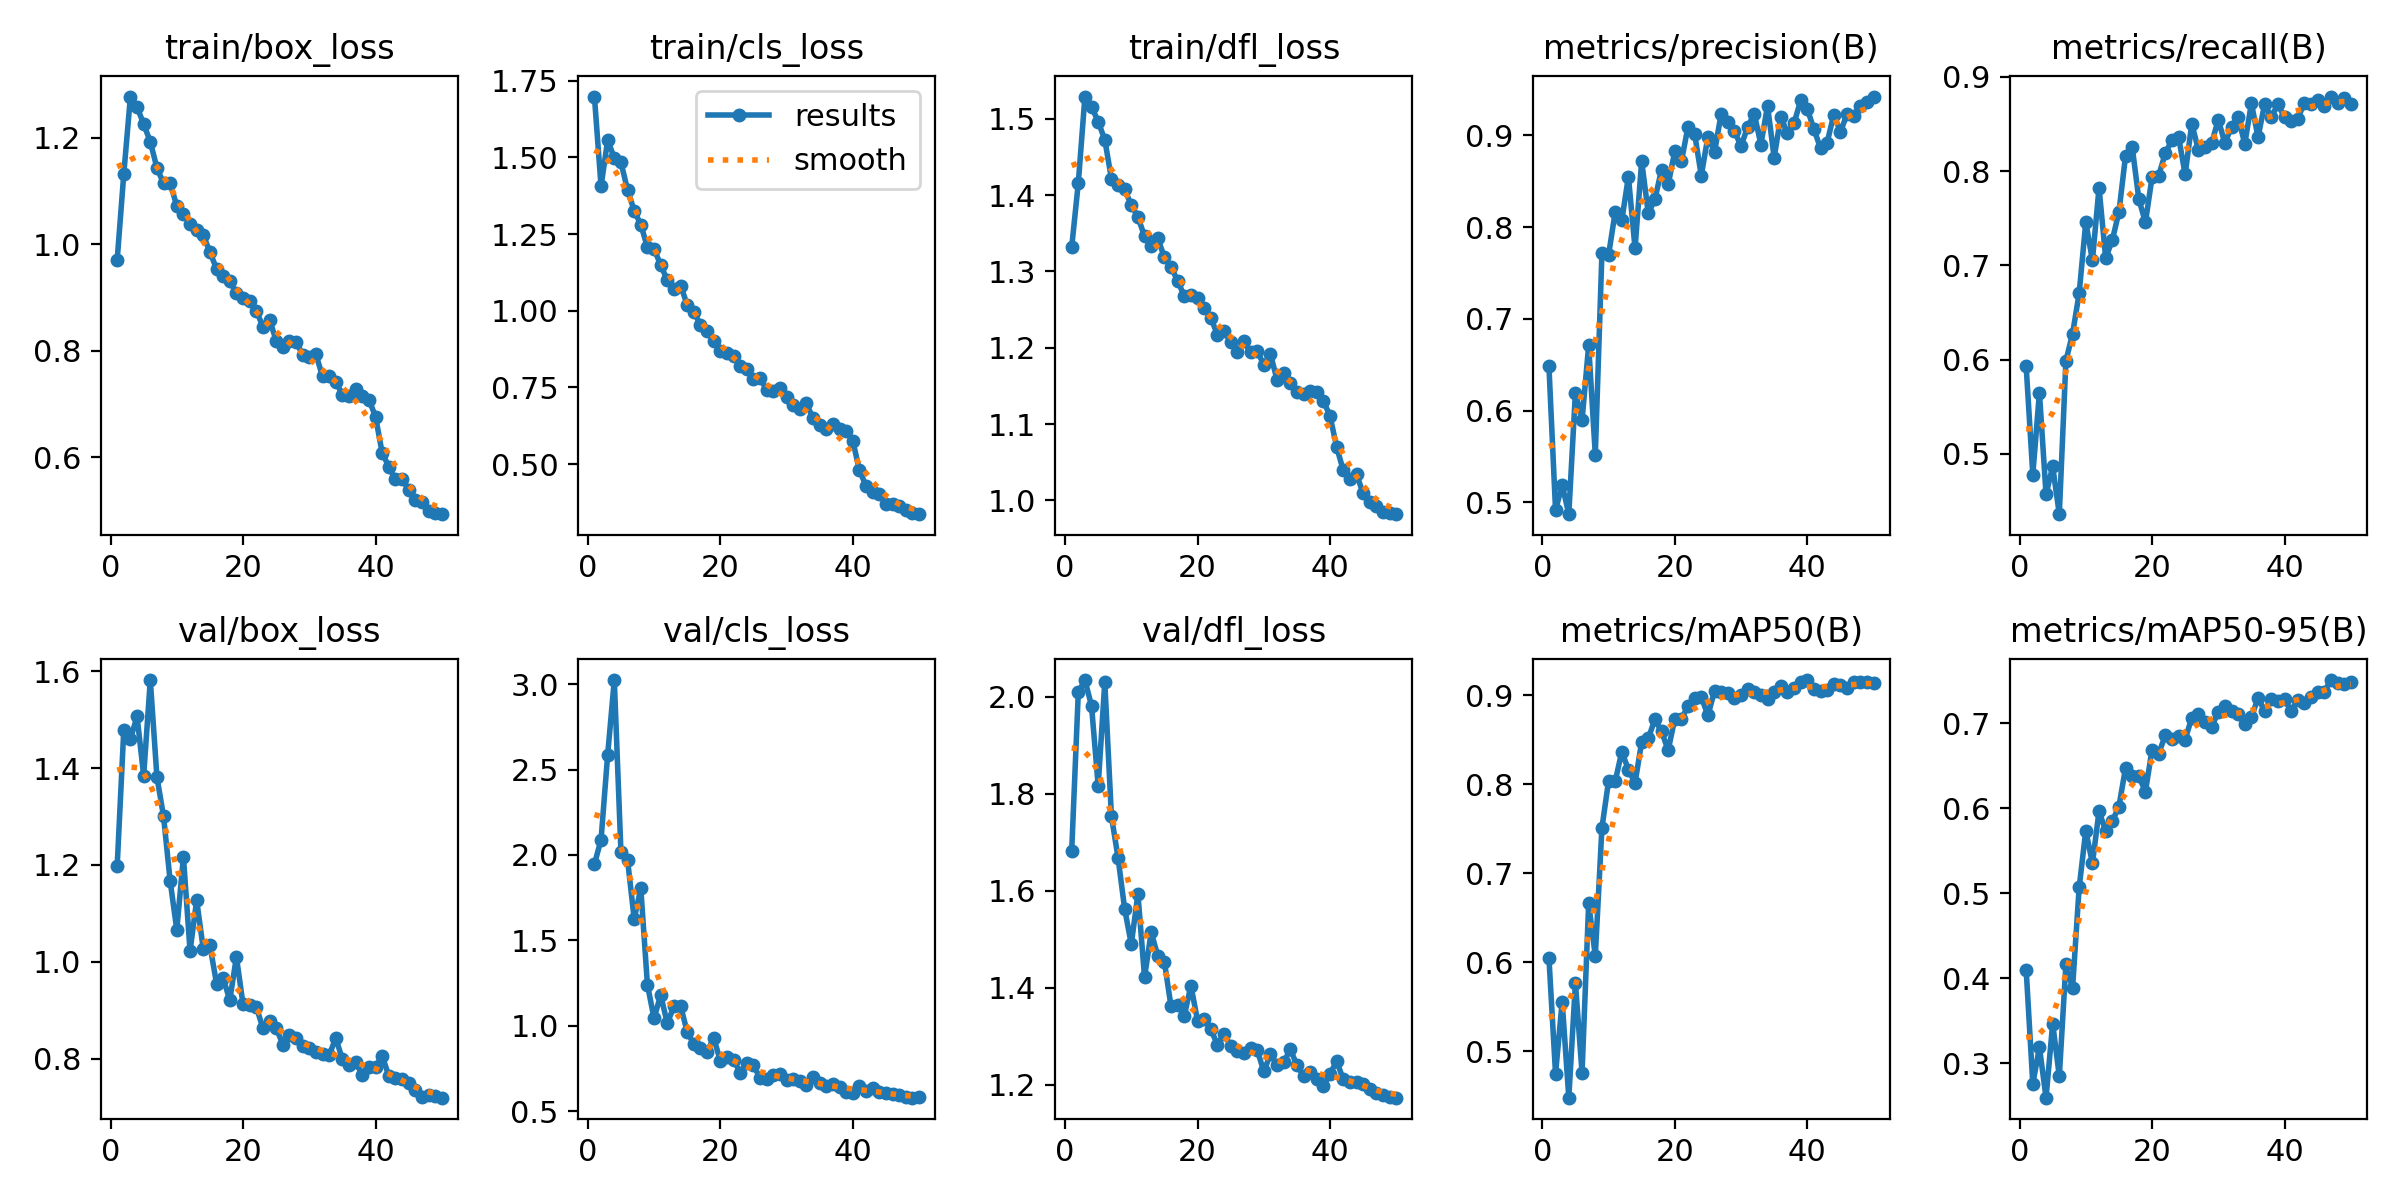

confusion_matrix.png


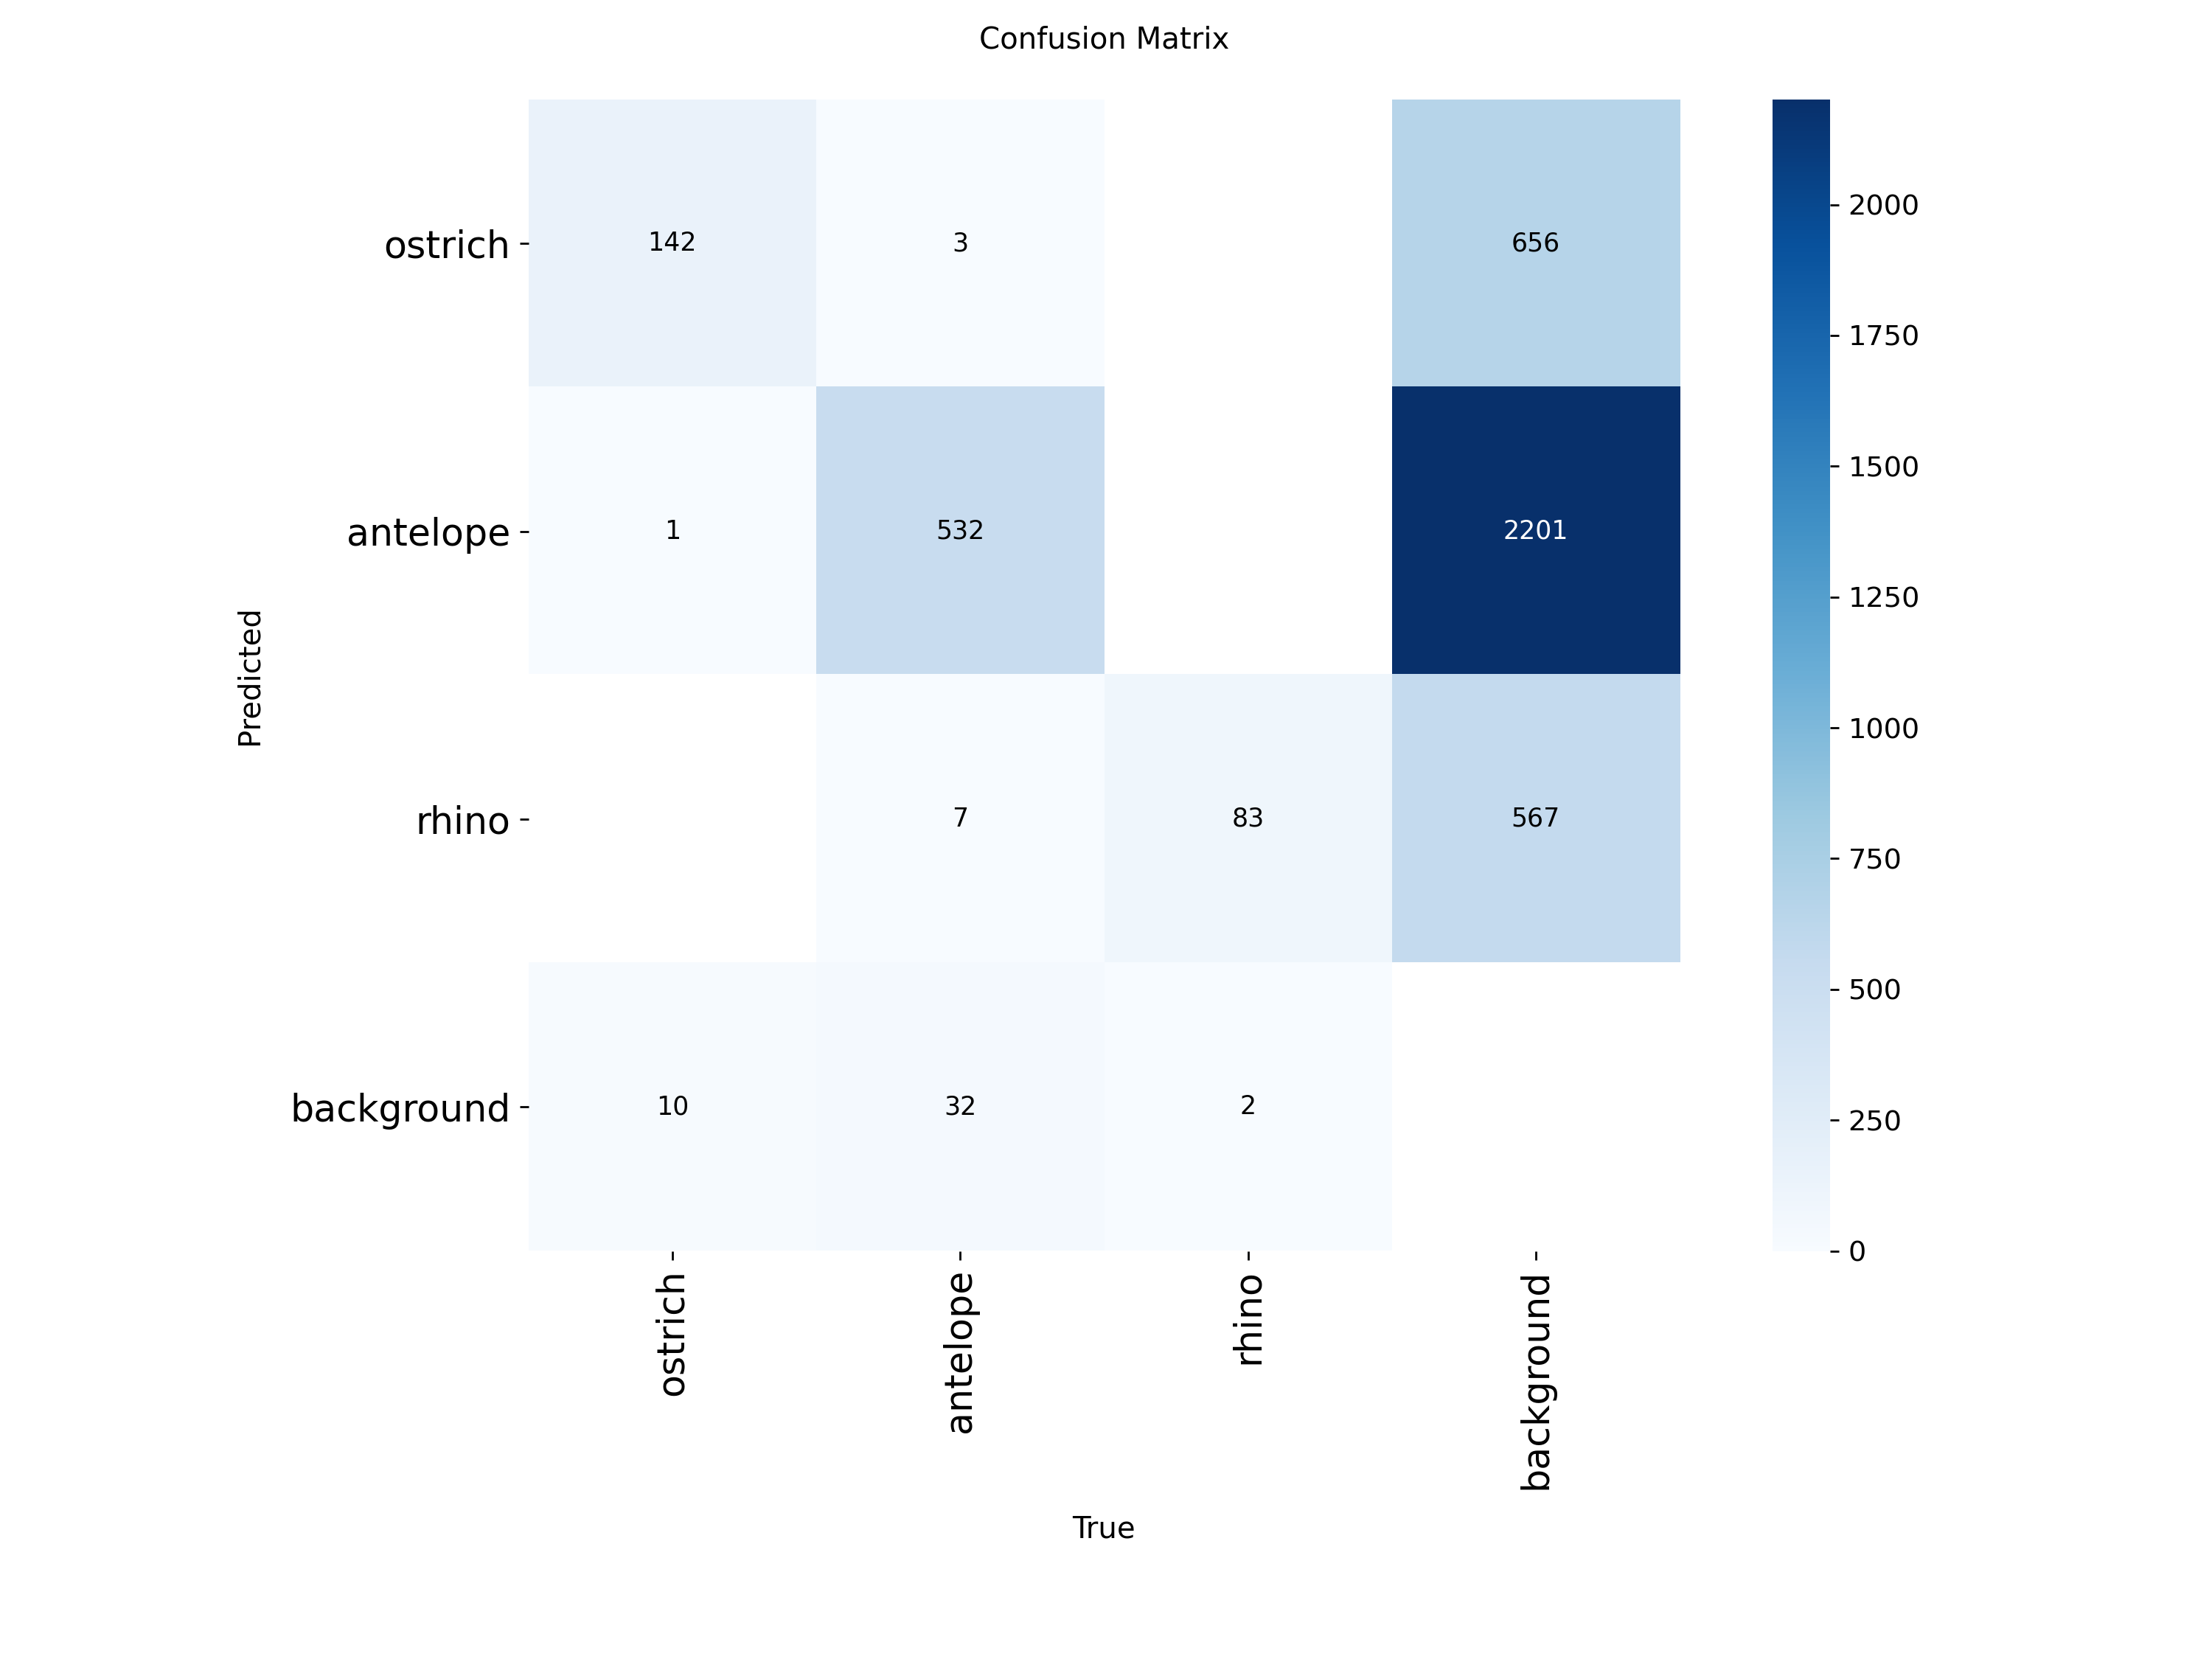

val_batch0_pred.jpg


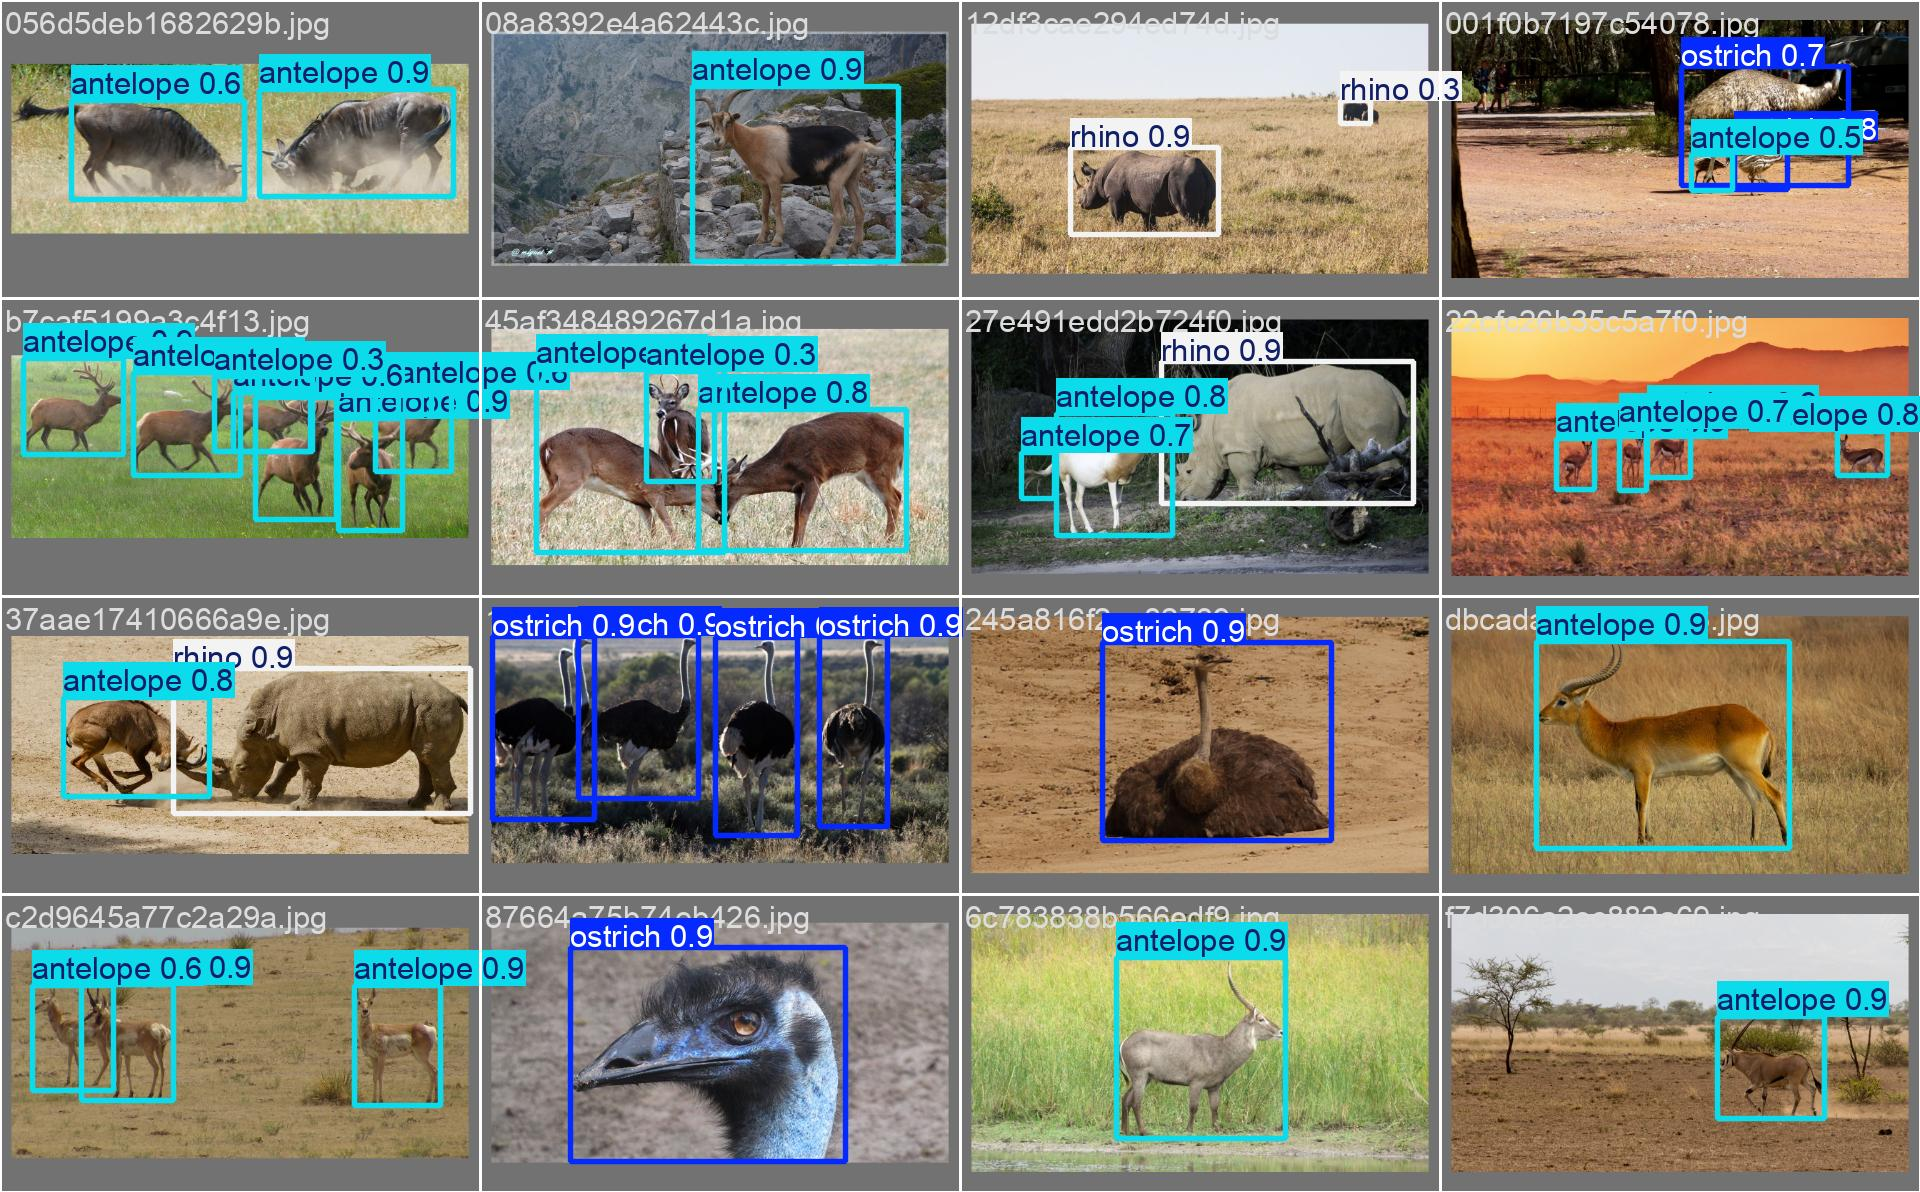

In [6]:
best = YOLO(BEST)
metrics = best.val(data=DATA_YAML)
print(f"mAP50    : {metrics.box.map50:.3f}")
print(f"mAP50-95 : {metrics.box.map:.3f}")
for name in ["results.png", "confusion_matrix.png", "PR_curve.png", "val_batch0_pred.jpg"]:
    p = os.path.join(RUN_DIR, name)
    if os.path.exists(p):
        print(name)
        display(Image(filename=p, width=800))

## 7. 객체 탐지 및 추적 영상 생성

- **입력 영상**: Pexels의 사바나 영상(3840×2160, 25fps)에서 0~7초 구간 사용
- **추적**: ByteTrack, 신뢰도 임계값 0.3
- **궤적**: ID별 박스 중심점의 최근 40프레임을 선으로 그려 이동 경로를 시각화
- **ID별 클래스 투표**: 개체끼리 겹칠 때 일시적으로 다른 클래스로 예측되는 문제가 있어, 같은 ID에 대해 지금까지의 예측을 신뢰도로 가중 합산하고 가장 높은 클래스로 표시한다. 이 경우 박스에 신뢰도 숫자는 표시하지 않는다.

In [7]:
VIDEO_IN = "/content/14729832_3840_2160_25fps.mp4"   # 입력 영상 (Pexels)

In [8]:
import cv2, torch
from collections import defaultdict, deque, Counter

START_SEC = 0        # 사용 구간 시작(초)
DURATION = 7         # 사용 구간 길이(초)
CONF = 0.3           # 탐지 신뢰도 임계값
TRAIL_LEN = 40       # 궤적으로 남길 최근 프레임 수
VOTE = True          # ID별 클래스 투표 사용 여부

tracker_model = YOLO(BEST)
cap = cv2.VideoCapture(VIDEO_IN)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.set(cv2.CAP_PROP_POS_FRAMES, int(START_SEC * fps))

RAW_OUT = "/content/track_raw.mp4"
writer = cv2.VideoWriter(RAW_OUT, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
trails = defaultdict(lambda: deque(maxlen=TRAIL_LEN))
votes = defaultdict(Counter)
for _ in range(int(DURATION * fps)):
    ok, frame = cap.read()
    if not ok:
        break
    r = tracker_model.track(frame, persist=True, tracker="bytetrack.yaml", conf=CONF, verbose=False)[0]
    if r.boxes.id is not None:
        ids = r.boxes.id.int().cpu().tolist()
        for c, p, tid in zip(r.boxes.cls.int().cpu().tolist(), r.boxes.conf.cpu().tolist(), ids):
            votes[tid][c] += p
        if VOTE:   # 표시 클래스를 ID별 투표 결과로 교체
            data = r.boxes.data.clone()
            data[:, -1] = torch.tensor([votes[t].most_common(1)[0][0] for t in ids],
                                       dtype=data.dtype, device=data.device)
            r.update(boxes=data)
        for (x, y, bw, bh), tid in zip(r.boxes.xywh.cpu().numpy(), ids):
            trails[tid].append((int(x), int(y)))
    canvas = r.plot(conf=not VOTE)   # 박스 + 클래스 + ID
    # 궤적 그리기
    for pts in trails.values():
        pts = list(pts)
        for a, b in zip(pts[:-1], pts[1:]):
            cv2.line(canvas, a, b, (0, 255, 255), 2)
    writer.write(canvas)
cap.release()
writer.release()

print("ID별 클래스 비율 (신뢰도 가중):")
for tid, cnt in sorted(votes.items()):
    total_v = sum(cnt.values())
    print(f"  id {tid}: " + ", ".join(f"{tracker_model.names[c]} {v / total_v:.0%}" for c, v in cnt.most_common()))

VIDEO_OUT = "/content/safari3_tracking.mp4"   # 브라우저 재생을 위해 H.264로 변환
!ffmpeg -y -loglevel error -i {RAW_OUT} -vcodec libx264 -preset veryfast -crf 23 -pix_fmt yuv420p {VIDEO_OUT}
print("결과 영상:", VIDEO_OUT)

ID별 클래스 비율 (신뢰도 가중):
  id 1: ostrich 100%
  id 2: rhino 85%, antelope 15%
  id 3: rhino 98%, ostrich 1%, antelope 0%
  id 4: antelope 85%, rhino 13%, ostrich 2%
  id 7: rhino 100%
  id 12: antelope 100%
  id 14: ostrich 99%, rhino 1%
  id 15: rhino 100%
결과 영상: /content/safari3_tracking.mp4
